<a href="https://colab.research.google.com/github/matti410/Trading-System-Creator_V4/blob/main/Trading_System_Lab_Crypto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trading System Lab · Crypto
### Dall'idea alla strategia verificata, in nove passi

La versione per le crypto, con i dati presi dagli exchange (Binance, Bybit) invece che dal broker CFD: ora UTC, mercato aperto 24 ore su 24, costi = commissione dell'exchange. Gli importi in «dollari» sono USDT.

Scegli tu i segnali di ingresso e le uscite. Lo strumento misura, scarta quello che non regge e ti dice quanto rischio aspettarti.

**Come si usa:** in ogni passo imposta i valori nel riquadro a destra, poi premi il tasto ▶ a sinistra della cella. I passi vanno eseguiti in ordine, dall'alto verso il basso.

## Avvio
Da eseguire una volta sola, all'inizio. Richiede circa un minuto.

Funziona su Colab e in locale. I dati **non** sono su GitHub: su Colab si leggono da Google Drive, cartella `Il mio Drive/Trading-System-Creator_V4/dati/` (al primo avvio Colab chiede il permesso di collegare Drive: scegli l'account e clicca **Consenti**); in locale dalla cartella `dati/` del progetto.

**I CSV crypto si scaricano sul PC**, non su Colab (Binance e Bybit bloccano i server di Colab, che sono negli Stati Uniti): dalla cartella del progetto lancia `python scarica_dati_crypto.py` (aggiungi `H1`, `H4`, ... per altri timeframe), poi carica i file `dati/BINANCE_*` e `dati/BYBIT_*` nella stessa cartella di Drive.

In [1]:
#@title Avvio { display-mode: "form" }
import os, shutil, subprocess, sys, warnings
warnings.simplefilter("ignore")

REPO = "matti410/Trading-System-Creator_V4"
CARTELLA = "/content/Trading-System-Creator_V4"
# I CSV dei dati NON sono su GitHub (dati/ e' nel .gitignore): su Colab si leggono
# da Google Drive, in locale dalla cartella dati/ del progetto (come nel notebook principale).
DATI_DRIVE = "/content/drive/MyDrive/Trading-System-Creator_V4/dati"

try:
    import google.colab  # noqa: F401
    SU_COLAB = True
except ImportError:
    SU_COLAB = False

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "TA-Lib==0.8.1", "backtesting==0.6.6"], check=True)

if SU_COLAB:
    # Il token di GitHub si legge dai Secrets di Colab (icona della chiave, a sinistra):
    # non va mai scritto qui dentro. Senza token si prova il repo pubblico.
    token = None
    try:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        pass

    os.chdir("/content")
    shutil.rmtree(CARTELLA, ignore_errors=True)
    indirizzo = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"
    esito = subprocess.run(["git", "clone", "--quiet", "--depth", "1", indirizzo, CARTELLA], capture_output=True, text=True)
    if esito.returncode != 0:
        raise RuntimeError("Non riesco a scaricare il progetto da GitHub. Se il repo è privato, controlla che il "
                           "secret GITHUB_TOKEN esista e che l'accesso dal notebook sia attivo.")
    os.chdir(CARTELLA)
    from google.colab import drive
    drive.mount("/content/drive")
    DATI_DIR = DATI_DRIVE
else:
    # in locale il notebook si apre dalla cartella del progetto
    DATI_DIR = os.path.join(os.getcwd(), "dati")

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
if not os.path.isdir(DATI_DIR):
    raise FileNotFoundError(f"Non trovo la cartella dei dati: {DATI_DIR}. "
                            + ("Carica i CSV di dati/ su Google Drive, in Il mio Drive/Trading-System-Creator_V4/dati/."
                               if SU_COLAB else "Apri il notebook dalla cartella del progetto e lancia prima scarica_dati_crypto.py."))
for nome in [m for m in sys.modules if m == "engine" or m.startswith("engine.")]:
    del sys.modules[nome]

%matplotlib inline
from IPython.utils.capture import capture_output
with capture_output():      # le librerie stampano avvisi tecnici al primo caricamento
    from engine.vetrina import (prepara, esplora, profilo_delle_ore, classifiche, rosa_dei_trigger, scegli_trigger,
                                imposta_uscite, rosa_dei_sistemi, trova_strategia, scheda,
                                money_management, verifica_trade, lente, stress_test)
print(f"Pronto. Dati da {DATI_DIR}")

Mounted at /content/drive
Pronto. Dati da /content/drive/MyDrive/Trading-System-Creator_V4/dati


## 1 · Configura
Scegli exchange, mercato, moneta e timeframe, e per quante barre osservare il prezzo dopo ogni segnale.

- **Mercato:** `PERP` = perpetual in USDT (long e short); `SPOT` = si compra la moneta, **solo long**.
- **Costi:** commissione *taker* per lato dal listino ufficiale, livello base (Binance perpetual 0,05%, Bybit perpetual 0,055%, spot 0,10%) più uno spread di un passo di prezzo. Tabella `COMMISSIONI` in `engine/exchange.py`.
- **Non ancora contato:** il funding dei perpetual.
- **Profilo orario e orari** delle condizioni `ORA_…` e `X_ORA_@…`: ora **UTC**.

In [21]:
#@title 1 · Configura { display-mode: "form" }
exchange = "BYBIT"  #@param ["BINANCE", "BYBIT"]
mercato = "PERP"  #@param ["PERP", "SPOT"]
moneta = "BTC"  #@param ["BTC", "ETH", "SOL", "XRP"]
timeframe = "M15"  #@param ["M5", "M15", "M30", "H1", "H4"]
#@markdown Orizzonte di osservazione, in barre del timeframe scelto (su M15: 4 barre = 1 ora).
orizzonte = 41  #@param {type:"slider", min:4, max:96, step:1}

strumento = f"{exchange}_{mercato}_{moneta}USDT"     # es. BINANCE_PERP_BTCUSDT (engine/simboli.py)
s = prepara(strumento, H=orizzonte, cartella=DATI_DIR, timeframe=timeframe)

,
Strumento,BYBIT_PERP_BTCUSDT
Barre M15,230.017
Periodo,28/03/2020 – 19/10/2026
In-sample (per costruire),"184.013 barre, fino al 27/06/2025"
Out-of-sample (mai visto),"46.004 barre, dal 27/06/2025"
Costo per trade,"commissione 0,055% per lato (taker) + spread di 0,10 pips (listino Bybit perp, livello base)"
Costo nel rollover,nessun rollover: mercato aperto 24 ore su 24
Orizzonte di osservazione,"41 barre (10,2 ore)"
Trigger disponibili,36 long · 35 short
Filtri disponibili,38


## 2 · Esplora
Cosa fa il prezzo dopo ogni segnale di ingresso? E, nella 2b: se apro un trade a una certa ora del giorno, guadagno più o meno del solito?

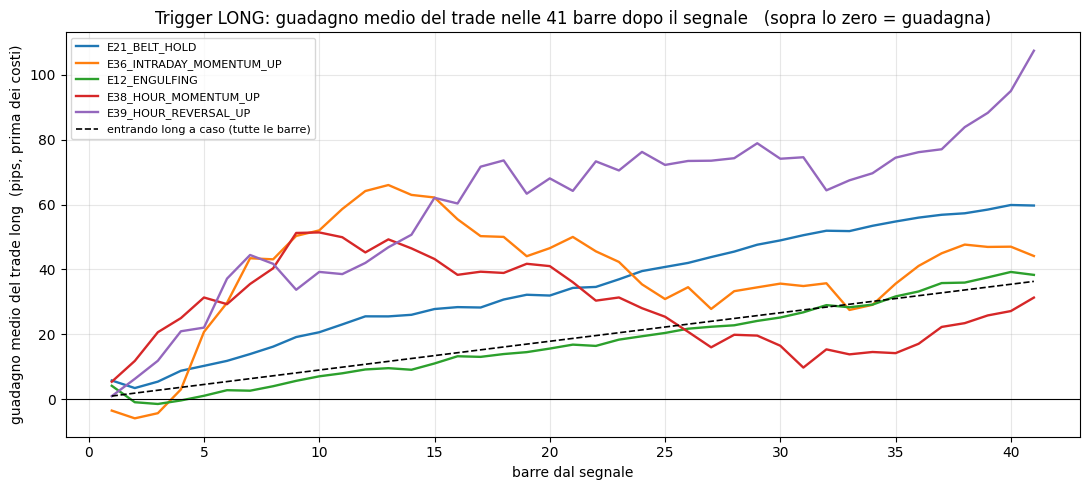

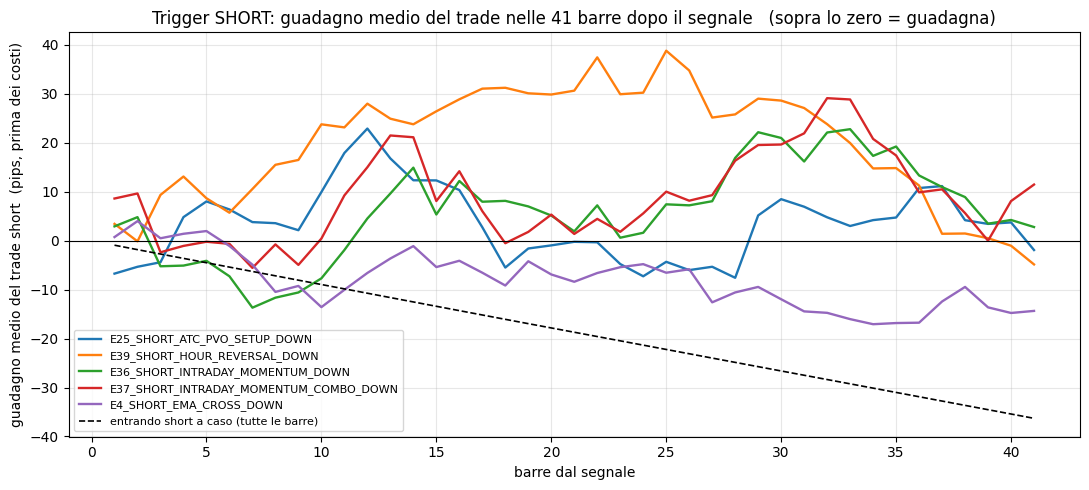

In [22]:
#@title 2 · Esplora { display-mode: "form" }
esplora(s);

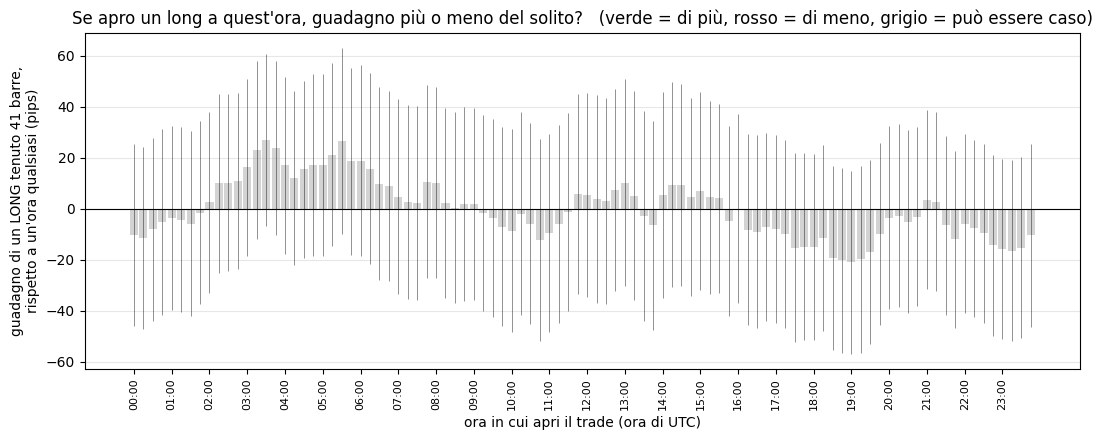

In [23]:
#@title 2b · Il profilo orario { display-mode: "form" }
profilo_delle_ore(s);

## 3 · Scegli i trigger
Le due classifiche, la rosa dei trigger suggeriti e poi la tua scelta.

In [24]:
#@title 3a · Le classifiche { display-mode: "form" }
classifiche(s);

Trigger,Movimento a favore (pips),Dopo quante barre,Occasioni,Solidità del segnale,Supera il rumore
E21_BELT_HOLD,"57,04",40,16.603,"5,17",sì
E36_INTRADAY_MOMENTUM_UP,"66,87",13,1.007,"4,29",sì
E12_ENGULFING,"39,51",40,23.244,"3,53",no
E38_HOUR_MOMENTUM_UP,"50,37",10,945,"3,52",no
E39_HOUR_REVERSAL_UP,"104,91",41,923,"3,34",no
E31_TRIPLE_SCREEN_UP,"45,87",23,2.264,"3,26",no
E8_CLOSING_PATTERN_ONLY,"43,63",40,7.822,"3,01",no
E22_ASIAN_RANGE_BREAKOUT,"109,60",37,790,"2,97",no
Trigger,Movimento a favore (pips),Dopo quante barre,Occasioni,Solidità del segnale,Supera il rumore
E25_SHORT_ATC_PVO_SETUP_DOWN,"22,13",12,1.530,"1,74",no


In [25]:
#@title 3a bis · La rosa dei trigger { display-mode: "form" }
rosa_dei_trigger(s);

Trigger,Lato,Occasioni,Più del mercato della stessa ora (pips),Solidità netta,Più del mercato a qualunque ora (pips),Supera la quota di fortuna,Regge sulle due metà,Famiglia,Nella rosa,Perché fuori
E21_BELT_HOLD,long,16.600,"18,36","2,96","18,35",sì,sì,6,sì,
E39_SHORT_HOUR_REVERSAL_DOWN,short,986,"56,16","2,33","50,69",sì,sì,38,sì,
E39_HOUR_REVERSAL_UP,long,923,"59,69","2,32","65,16",sì,sì,37,sì,
E40_JUMP_MOMENTUM_UP,long,249,"154,92","2,28","155,11",sì,sì,39,sì,


In [35]:
#@title 3b · La tua scelta { display-mode: "form" }
#@markdown **Spot: lascia vuoto il lato short** (lo short non esiste).
#@markdown Copia i nomi dalla classifica. Più nomi sullo stesso lato: separali con una virgola. Lato vuoto = spento.
#@markdown Trigger a orario: `ORA_LONG_@12:30` o `ORA_SHORT_@12:30` = entra ogni giorno a quell'ora (ora UTC, come il profilo 2b).
trigger_long = ""  #@param {type:"string"}
trigger_short = "ORA_SHORT_@05:30"  #@param {type:"string"}

scegli_trigger(s, long=trigger_long, short=trigger_short)

Lato,Trigger scelti
LONG,nessuno (lato spento)
SHORT,ORA_SHORT_@05:30


## 4 · Imposta le uscite
Dopo quante barre chiudere, quanto larghi tenere stop e target e, se vuoi, una regola oraria. Poi la rosa dei sistemi.

Backtest.run:   0%|          | 0/184012 [00:00<?, ?bar/s]

Sistema,Trade,Guadagno medio netto per trade (pips),Trade vincenti (%),Solidità,Durata media (barre)
Solo short,1.838,"-89,02","43,31","-3,84","47,9"


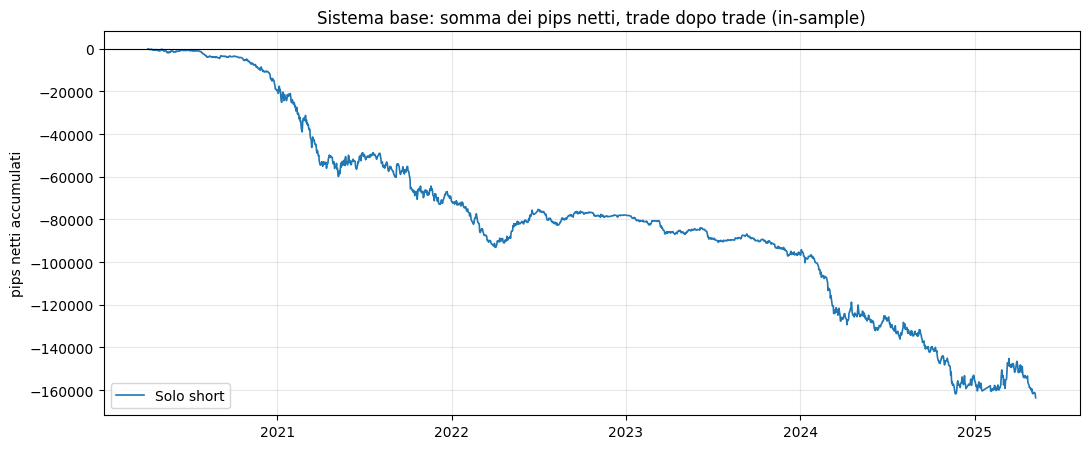

In [36]:
#@title 4 · Imposta le uscite { display-mode: "form" }
#@markdown Uscita a tempo, in barre (può essere diversa fra long e short)
barre_long = 76  #@param {type:"slider", min:1, max:96, step:1}
barre_short = 64  #@param {type:"slider", min:1, max:96, step:1}
#@markdown Stop e target adattivi, come percentile (0 = spento)
stop = 90  #@param {type:"slider", min:0, max:99, step:1}
target = 0  #@param {type:"slider", min:0, max:99, step:1}
#@markdown Regola oraria (facoltativa): `X_ORA_@16:00` chiude alle 16:00 UTC; `X_INVERSIONE_TREND` chiude quando arriva un'ora rossa (per il long) o verde (per lo short) del profilo 2b; `X_ORA_@17:00` è l'uscita del momentum intraday (E36, E37: si entra alle 16:30) e del momentum dopo un salto (E40); `X_ORA_@22:00_UTC` e `X_ORA_@13:00_UTC` chiudono all'ora UTC fissa, per le coppie di ore E38 (si entra alle 21:00 UTC) ed E39 (alle 12:00 UTC)
regola_uscita = "X_ORA_@18:00"  #@param ["nessuna", "X_INVERSIONE_TREND", "X_ORA_@16:00", "X_ORA_@17:00", "X_ORA_@22:00_UTC", "X_ORA_@13:00_UTC"] {allow-input: true}

imposta_uscite(s, barre_long=barre_long, barre_short=barre_short, sl=stop, tp=target,
               regola_uscita=regola_uscita);

In [37]:
#@title 4b · La rosa dei sistemi { display-mode: "form" }
rosa_dei_sistemi(s);

Sistema,Trade,"Più del mercato della stessa ora, per trade (pips netti)",Solidità netta,"Più del mercato a qualunque ora, per trade (pips netti)",Supera la quota di fortuna,Regge sulle due metà,Nella rosa,Perché fuori
Solo short,1.838,"-40,62","-1,75","-62,87",no,no,no,non fa meglio del mercato


## 5 · Trova la strategia
Lo strumento prova tutti i filtri disponibili sul tuo sistema base. Richiede circa mezzo minuto.

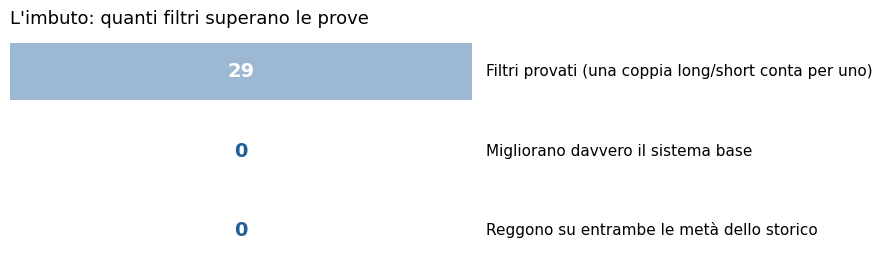

Filtro,Trade,Guadagno medio netto per trade (pips),Miglioramento sul sistema base (pips),Solidità del miglioramento,Prima prova,Seconda prova (due metà)
Sistema base (nessun filtro),1.838,"-89,02",—,—,—,—
F25_CHOP_TREND,675,"-41,68","114,92","2,39",non passa: in perdita dopo i costi,—
F9_DOWNTREND_CONTEXT,912,"-59,43","81,11","1,75",non passa: in perdita dopo i costi,—
F2_MID_VOLATILITY,1.634,"-77,10","107,20","1,38",non passa: in perdita dopo i costi,—
F4_MACD_BELOW_SIGNAL,1.016,"-69,66","60,04","1,30",non passa: in perdita dopo i costi,—
F3_VOLUME_ABOVE_AVG,522,"-61,58","46,50","0,89",non passa: in perdita dopo i costi,—
F39_INSIDE_DAY,396,"-79,35","40,11","0,79",non passa: in perdita dopo i costi,—
F14_LOW_DRIFT_REGIME,604,"-82,80","35,50","0,74",non passa: in perdita dopo i costi,—
F1_ADX_ABOVE,1.156,"-98,37","33,31","0,71",non passa: in perdita dopo i costi,—


CPU times: user 7.42 s, sys: 656 ms, total: 8.07 s
Wall time: 40.6 s


,Filtro,Trade,Guadagno medio netto per trade (pips),Miglioramento sul sistema base (pips),Solidità del miglioramento,Prima prova,Seconda prova (due metà)
0,Sistema base (nessun filtro),1838,-89.020177,NaN,NaN,—,—
1,F25_CHOP_TREND,675,-41.675342,114.921638,2.387030,non passa: in perdita dopo i costi,—
2,F9_DOWNTREND_CONTEXT,912,-59.425900,81.112824,1.748737,non passa: in perdita dopo i costi,—
3,F2_MID_VOLATILITY,1634,-77.103636,107.204688,1.380092,non passa: in perdita dopo i costi,—
4,F4_MACD_BELOW_SIGNAL,1016,-69.657978,60.035919,1.296591,non passa: in perdita dopo i costi,—
5,F3_VOLUME_ABOVE_AVG,522,-61.579845,46.498110,0.886968,non passa: in perdita dopo i costi,—
6,F39_INSIDE_DAY,396,-79.354020,40.113170,0.788947,non passa: in perdita dopo i costi,—
7,F14_LOW_DRIFT_REGIME,604,-82.802257,35.495141,0.742531,non passa: in perdita dopo i costi,—
8,F1_ADX_ABOVE,1156,-98.373443,33.308320,0.714530,non passa: in perdita dopo i costi,—


In [38]:
#@title 5 · Trova la strategia { display-mode: "form" }
%%time
trova_strategia(s);

## 6 · Scheda strategia
La prova sui dati che la strategia non ha mai visto.

,In-sample,Out-of-sample
Trade,675,180
Guadagno medio netto per trade (pips),"-41,68","278,58"
Totale pips netti,-28.131,50.144
Trade vincenti (%),"45,2","56,1"
Vincenti necessari per il pareggio (%),"48,3","41,8"
Vincita media / perdita media,"1,07","1,39"
Profit factor,"0,88","1,78"
Solidità,"-1,08","2,91"
Probabilità che in realtà perda (%),"86,7","0,1"
Drawdown massimo (pips),33.700,7.159


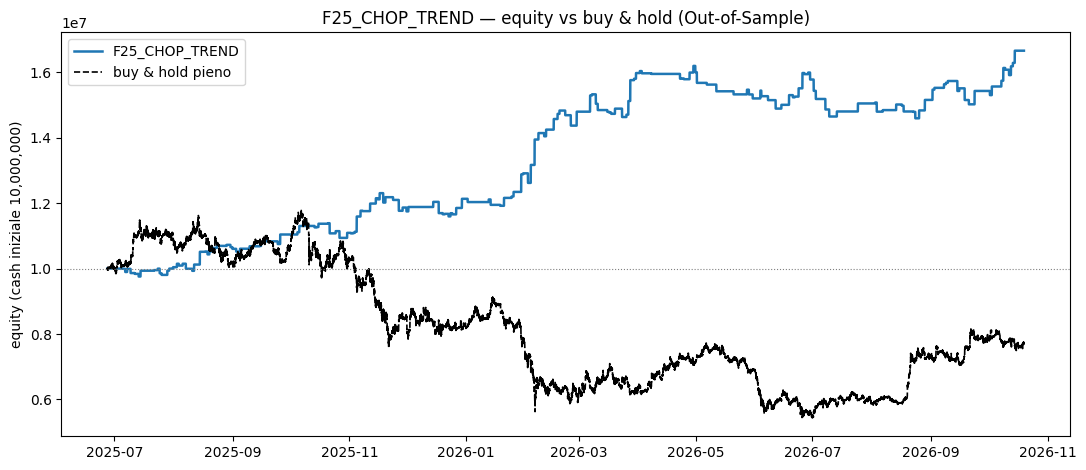

In [39]:
#@title 6 · Scheda strategia { display-mode: "form" }
#@markdown Uno o più filtri copiati dalla classifica, separati da virgola: si entra solo quando sono veri tutti. Vuoto = sistema base, senza filtro.
filtro = "F25_CHOP_TREND"  #@param {type:"string"}

scheda(s, filtro=filtro);

## 7 · Money management
Quanto rischiare su ogni trade, in percentuale del conto (in USDT). 1 lotto = 1 moneta; quantità minima e passo sono quelli dell'exchange. Leva massima concessa in Italia: 2 sui perpetual, 1 sullo spot. La percentuale la sceglie lo strumento sui soli dati in-sample, con la tua regola sul drawdown; poi mostra cosa avrebbe fatto il conto sui dati mai visti. Due modelli a confronto, rischio fisso e volatilità. Richiede circa un minuto.

Modello,Percentuale scelta (%),Drawdown tipico (%),"Drawdown nel caso sfortunato, 1 su 20 (%)",Rendimento tipico (%),Probabilità di chiudere in perdita (%),Trade saltati (%)
volatilità ◀ in uso,"1,25","9,8","17,9","-5,7","78,8","0,0"
rischio fisso,"1,25","10,1","18,5","-4,8","72,9","0,0"


,
Trade in-sample,675
"Volatilità mediana per trade (ATR a 5 giornate, pips)","1.708,2"
Volatilità media per trade (pips),"1.902,8"
Volatilità mediana con 1 lotto ($),"1.708,20 $"
Trade che hanno perso più di 1 ATR (%),"4,0"
Perdita peggiore (in ATR),"-1,92"
Trade senza misura (saltati),0
Kelly (riferimento),"-8,95 %"
Optimal f (riferimento),"0,00 %"
Trade a grappoli? (z-score),"2,58 · vincite e perdite si alternano più del caso"


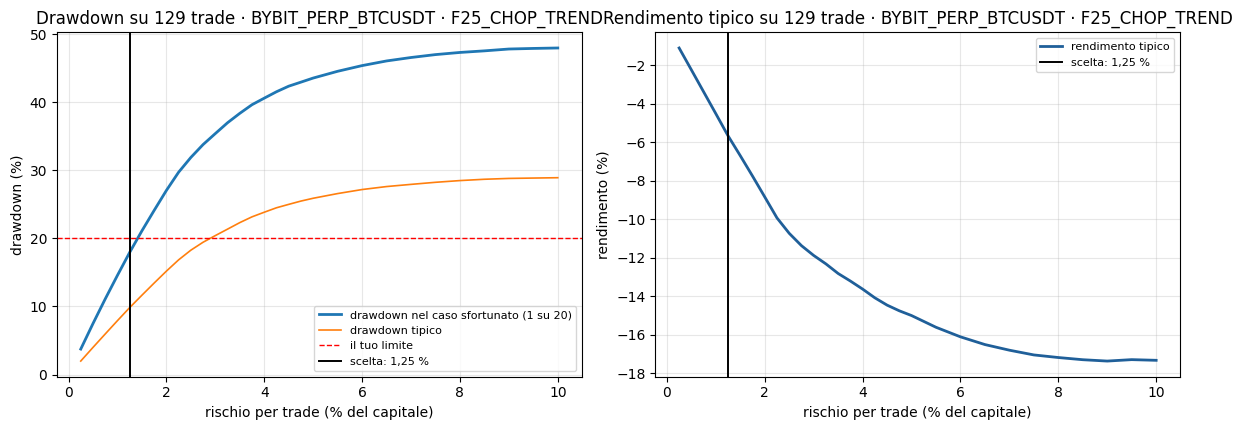

,In-sample (storia vera),Out-of-sample
Trade,675,180
Trade fatti,675,180
Trade saltati,0,0
Volte in cui interviene la leva,2,0
Capitale iniziale ($),10.000,10.000
Capitale finale ($),7.431,12.386
Rendimento (%),"-25,7","23,9"
Drawdown massimo (%),"25,7","4,1"
Perdita peggiore su un trade (% del conto),"2,37","1,07"
Lotti minimi,"0,01","0,02"


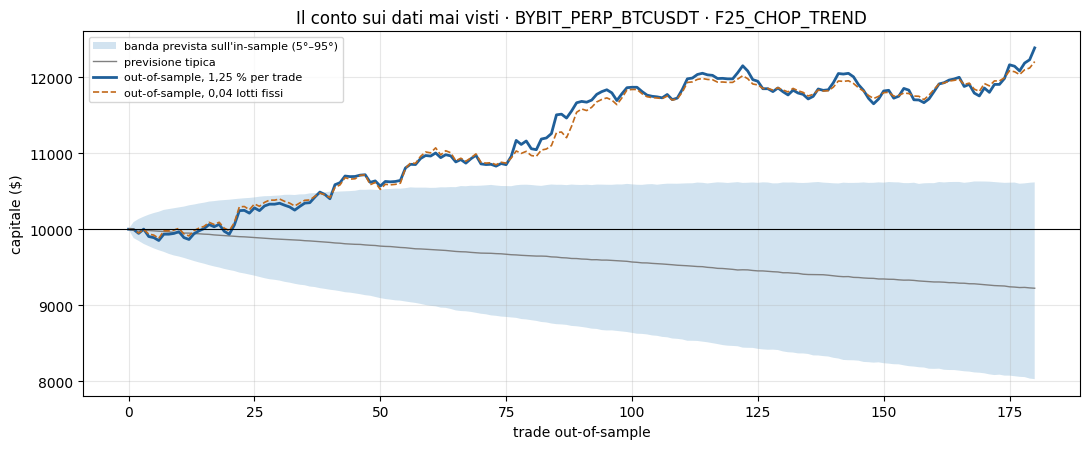

Dopo,Trade (circa),Drawdown tipico (%),"Drawdown da allarme, 1 su 20 (%)","Drawdown da fermarsi, 1 su 100 (%)","Rendimento sfortunato, 1 su 20 (%)",Rendimento tipico (%),Probabilità di essere in perdita (%)
3 mesi,32,"3,9","7,9","9,8","-6,9","-1,4","65,6"
6 mesi,64,"6,2","11,8","14,6","-10,4","-2,8","71,2"
12 mesi,129,"9,8","17,9","21,4","-16,0","-5,7","78,8"


In [43]:
#@title 7 · Money management { display-mode: "form" }
#@markdown Il conto con cui partiresti, il calo massimo dal massimo che accetti e su quanto tempo vale questa regola.
capitale_iniziale_in_dollari = 10000  #@param {type:"number"}
drawdown_massimo_accettato_pct = 20  #@param {type:"number"}
orizzonte_anni = 1  #@param {type:"number"}
#@markdown Come si misura il rischio di un trade: «volatilità» (quanto si è mosso il mercato negli ultimi 5 giorni) o «rischio fisso» (dove sta lo stop). I due modelli si confrontano comunque sull'in-sample: sceglilo prima di guardare l'out-of-sample.
modello = "volatilità"  #@param ["volatilità", "rischio fisso"]
#@markdown Leva massima del conto (nozionale ≤ capitale × leva). 0 = la massima concessa in Italia a un cliente al dettaglio per questo strumento (`engine/simboli.py`); un valore più alto si ferma con un errore.
leva = 1  #@param {type:"number"}

money_management(s, capitale=capitale_iniziale_in_dollari,
                 drawdown_max_pct=drawdown_massimo_accettato_pct, anni=orizzonte_anni,
                 modello=modello, leva=leva);

## 8 · Verifica i trade
Il backtest è entrato davvero dove dicono le tue regole?

In [ ]:
#@title 8a · Controllo automatico { display-mode: "form" }
verifica_trade(s);

In [ ]:
#@title 8b · La lente sul trade { display-mode: "form" }
periodo = "out-of-sample"  #@param ["out-of-sample", "in-sample"]
#@markdown Numero del trade (0 = uno a caso), oppure una data: apre il primo trade da quel giorno.
numero = 0  #@param {type:"integer"}
data = ""  #@param {type:"string"}
#@markdown Indicatori da disegnare, separati da virgola (l'elenco di quelli disponibili è sotto il grafico).
indicatori = ""  #@param {type:"string"}
#@markdown Disegna anche la regola dei trigger scattati: nome, candele della figura, livello rotto, indicatori che la regola legge.
mostra_trigger = True  #@param {type:"boolean"}
barre_prima = 40  #@param {type:"slider", min:10, max:200, step:5}
barre_dopo = 25  #@param {type:"slider", min:5, max:200, step:5}

lente(s, periodo=periodo, numero=numero, data=data, indicatori=indicatori,
      barre_prima=barre_prima, barre_dopo=barre_dopo, mostra_trigger=mostra_trigger);

## 9 · Stress test
Quanto drawdown aspettarsi, e con quanti lotti partire.

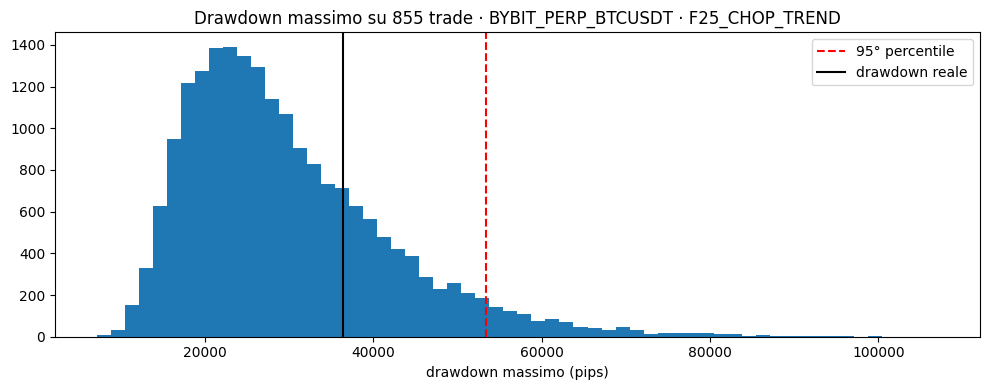

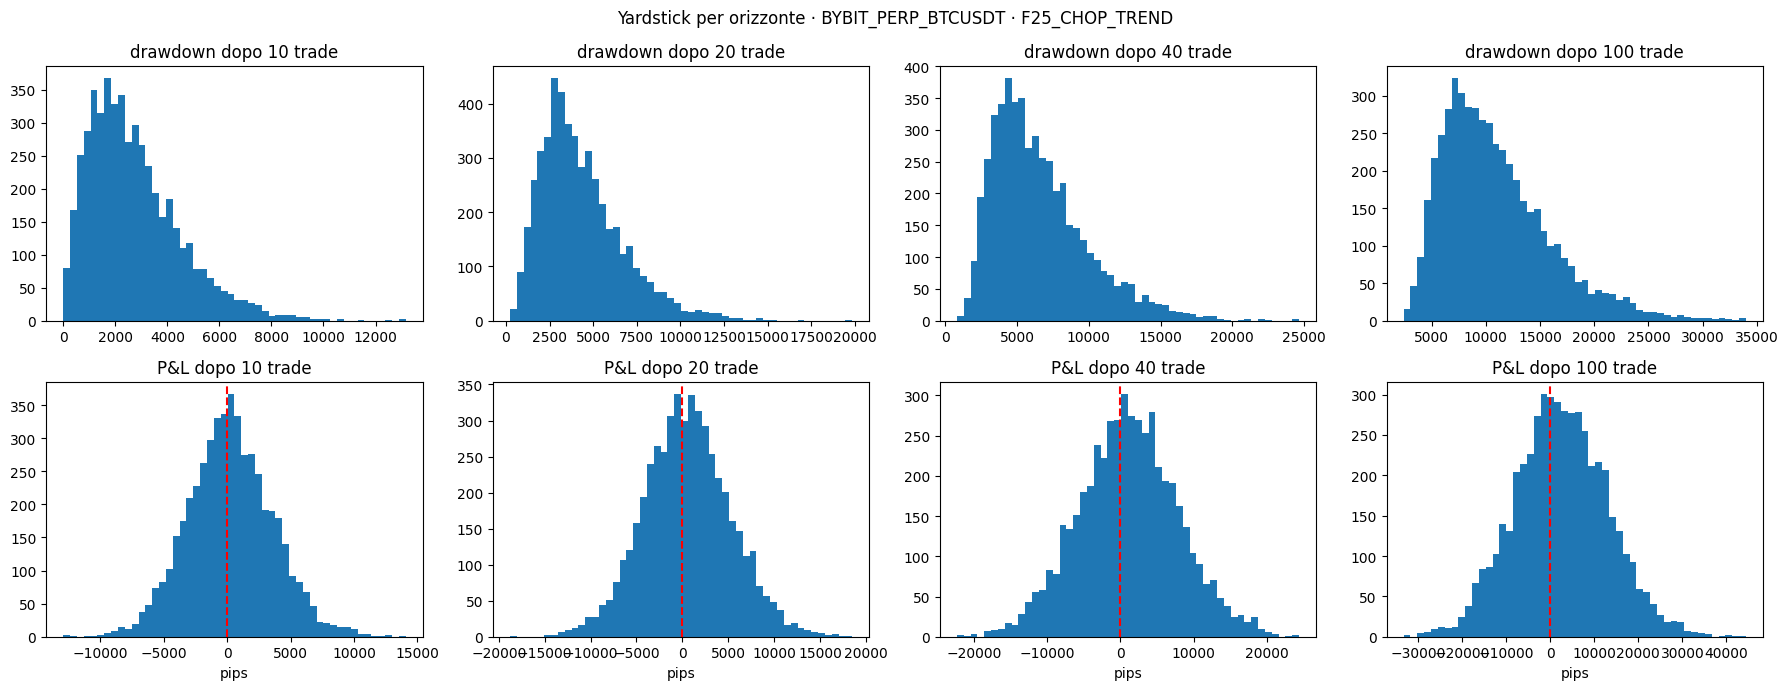

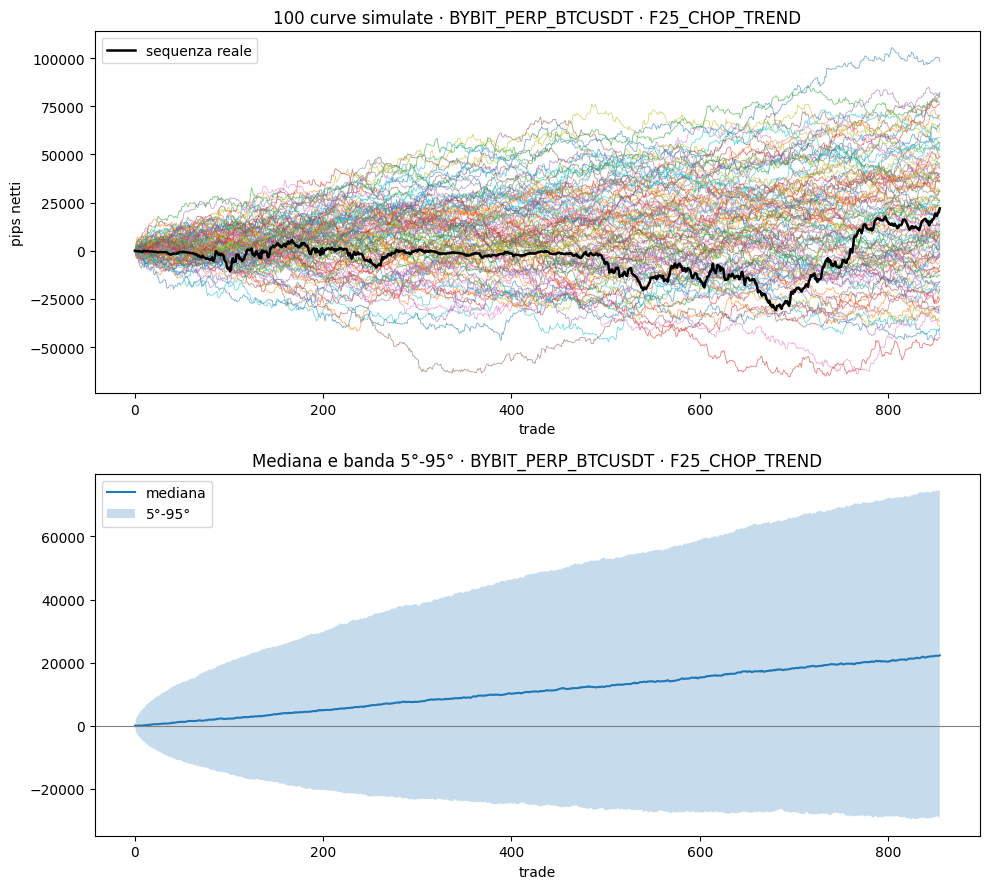

In [42]:
#@title 9 · Stress test { display-mode: "form" }
#@markdown Se hai eseguito la sezione 7, il drawdown viene da lì (capitale × drawdown %) e questo campo non si usa.
drawdown_massimo_in_dollari = 10000  #@param {type:"number"}

stress_test(s, drawdown_max_usd=drawdown_massimo_in_dollari);